# 30 Logistic Regression Programs for Data Science
A complete collection of classification programs covering sigmoid math from scratch, Scikit-Learn pipelines, regularizations, diagnostics, statsmodels analysis, and deep learning implementations.

## 1. Fundamentals & Math From Scratch

### 1. Sigmoid Function Implementation

In [30]:
import numpy as np

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

z_values = np.array([-5.0, 0.0, 5.0])
print("Probabilities:", sigmoid(z_values))

Probabilities: [0.00669285 0.5        0.99330715]


### 2. Binary Cross-Entropy Loss (Log Loss)

In [31]:
import numpy as np

def log_loss(y_true, y_pred, eps=1e-15):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

y_true = np.array([1, 0, 1, 1])
y_pred = np.array([0.9, 0.1, 0.8, 0.4])
print("Log Loss:", log_loss(y_true, y_pred))

Log Loss: 0.3375388286260043


### 3. Binary Logistic Regression via Gradient Descent (Scratch)

In [32]:
import numpy as np

class LogisticRegressionScratch:
    def __init__(self, lr=0.01, epochs=1000):
        self.lr, self.epochs = lr, epochs
        self.w, self.b = None, None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0

        for _ in range(self.epochs):
            linear_model = np.dot(X, self.w) + self.b
            y_predicted = 1 / (1 + np.exp(-np.clip(linear_model, -500, 500)))

            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict_proba(self, X):
        return 1 / (1 + np.exp(-np.clip(np.dot(X, self.w) + self.b, -500, 500)))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

X = np.array([[1, 2], [2, 3], [3, 1], [4, 3], [5, 5]])
y = np.array([0, 0, 0, 1, 1])
model = LogisticRegressionScratch()
model.fit(X, y)
print("Scratch Predictions:", model.predict(X))

Scratch Predictions: [0 0 1 1 1]


### 4. Newton-Raphson Optimization

In [33]:
import numpy as np

def newton_raphson_logistic(X, y, max_iter=10):
    n_samples, n_features = X.shape
    X = np.hstack([np.ones((n_samples, 1)), X])
    w = np.zeros(n_features + 1)

    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-np.dot(X, w)))
        p = np.clip(p, 1e-15, 1 - 1e-15)
        W = np.diag(p * (1 - p))
        grad = np.dot(X.T, (p - y))
        hessian = np.dot(X.T, np.dot(W, X))
        w -= np.linalg.inv(hessian) @ grad
    return w

X = np.array([[1.0], [2.0], [3.0], [4.0]])
y = np.array([0, 0, 1, 1])
weights = newton_raphson_logistic(X, y)
print("Newton-Raphson Weights:", weights)

Newton-Raphson Weights: [-46.67833607  18.67133443]


## 2. Scikit-Learn Model Training & Decision Boundaries

### 5. Basic Binary Classification with Scikit-Learn

In [34]:
from sklearn.linear_model import LogisticRegression
import numpy as np

X = np.array([[1, 2], [2, 3], [3, 1], [4, 3], [5, 5]])
y = np.array([0, 0, 0, 1, 1])

clf = LogisticRegression().fit(X, y)
print("Class Predictions:", clf.predict([[3, 3]]))
print("Predicted Probabilities:", clf.predict_proba([[3, 3]]))

Class Predictions: [0]
Predicted Probabilities: [[0.59766743 0.40233257]]


### 6. Probability Threshold Modification

In [35]:
from sklearn.linear_model import LogisticRegression
import numpy as np

X = np.random.randn(100, 2)
y = (X[:, 0] + X[:, 1] > 0).astype(int)
clf = LogisticRegression().fit(X, y)

probs = clf.predict_proba(X)[:, 1]
custom_preds = (probs >= 0.3).astype(int)
print("Custom Threshold First 5 Predictions:", custom_preds[:5])

Custom Threshold First 5 Predictions: [0 1 1 1 1]


### 7. Decision Boundary Visualization Plot

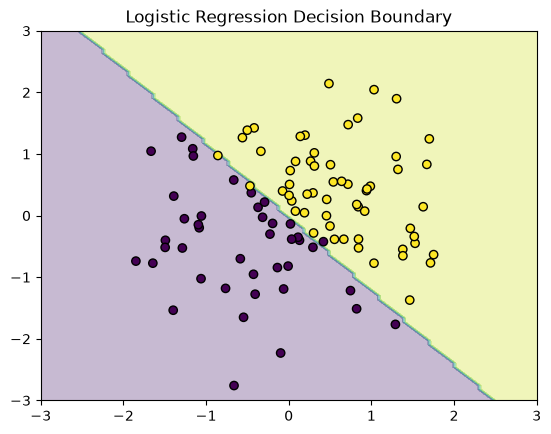

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

X = np.random.randn(100, 2)
y = (X[:, 0] + X[:, 1] > 0).astype(int)
clf = LogisticRegression().fit(X, y)

xx, yy = np.meshgrid(np.linspace(-3, 3, 100), np.linspace(-3, 3, 100))
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k')
plt.title("Logistic Regression Decision Boundary")
plt.show()

### 8. Multinomial Logistic Regression (Softmax)

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_iris

X, y = load_iris(return_X_y=True)
clf = LogisticRegression(solver='lbfgs', max_iter=200).fit(X, y)
print("Multinomial Classes Detected:", clf.classes_)
print("Logits Shape:", clf.coef_.shape)

Multinomial Classes Detected: [0 1 2]
Logits Shape: (3, 4)


### 9. One-vs-Rest (OvR) Multi-class Strategy

In [38]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

X, y = load_iris(return_X_y=True)

# Use OneVsRestClassifier to explicitly enforce OvR strategy
clf = OneVsRestClassifier(LogisticRegression(solver="liblinear")).fit(X, y)

# Access individual binary estimators to get the OvR intercepts
print("OvR Intercepts:", [estimator.intercept_[0] for estimator in clf.estimators_])

OvR Intercepts: [np.float64(0.26421852991732486), np.float64(1.0939246713654251), np.float64(-1.2147091659246076)]


## 3. Regularization & Optimization Solvers

### 10. L2 Regularization (Ridge Logistic Regression)

In [39]:
from sklearn.linear_model import LogisticRegression
import numpy as np

X = np.random.randn(50, 10)
y = np.random.randint(0, 2, 50)

clf = LogisticRegression(penalty='l2', C=0.01, solver='lbfgs').fit(X, y)
print("Regularized Weights Norm:", np.linalg.norm(clf.coef_))

Regularized Weights Norm: 0.08340493890861175


/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### 11. L1 Regularization (Lasso for Feature Selection)

In [40]:
from sklearn.linear_model import LogisticRegression
import numpy as np

X = np.random.randn(50, 10)
y = np.random.randint(0, 2, 50)

clf = LogisticRegression(penalty='l1', C=0.1, solver='liblinear').fit(X, y)
print("Sparsified Coefficients:", clf.coef_)

Sparsified Coefficients: [[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


### 12. ElasticNet Penalty with Saga Solver

In [41]:
from sklearn.linear_model import LogisticRegression
import numpy as np

X, y = np.random.randn(100, 5), np.random.randint(0, 2, 100)
clf = LogisticRegression(penalty='elasticnet', l1_ratio=0.5, C=0.5, solver='saga', max_iter=500).fit(X, y)
print("ElasticNet Coefficients:", clf.coef_)

ElasticNet Coefficients: [[ 0.05495981  0.          0.35840102 -0.48011722 -0.34324402]]


/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### 13. LogisticRegressionCV for Automatic C Tuning

In [42]:
from sklearn.linear_model import LogisticRegressionCV
import numpy as np

X, y = np.random.randn(100, 5), np.random.randint(0, 2, 100)
clf = LogisticRegressionCV(Cs=10, cv=5, penalty='l2').fit(X, y)
print("Best Regularization Strength C:", clf.C_[0])

Best Regularization Strength C: 0.046415888336127774


/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2123: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.war

## 4. Evaluation Metrics & Diagnostics

### 14. Confusion Matrix Analysis

In [43]:
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
import numpy as np

X, y = np.random.randn(100, 2), np.random.randint(0, 2, 100)
model = LogisticRegression().fit(X, y)
print("Confusion Matrix:\n", confusion_matrix(y, model.predict(X)))

Confusion Matrix:
 [[ 1 35]
 [ 1 63]]


### 15. Classification Report

In [44]:
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
import numpy as np

X, y = np.random.randn(100, 2), np.random.randint(0, 2, 100)
model = LogisticRegression().fit(X, y)
print(classification_report(y, model.predict(X)))

              precision    recall  f1-score   support

           0       0.58      0.60      0.59        50
           1       0.58      0.56      0.57        50

    accuracy                           0.58       100
   macro avg       0.58      0.58      0.58       100
weighted avg       0.58      0.58      0.58       100



### 16. ROC Curve and AUC Score

In [45]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression
import numpy as np

X, y = np.random.randn(100, 2), np.random.randint(0, 2, 100)
model = LogisticRegression().fit(X, y)
probs = model.predict_proba(X)[:, 1]
print(f"ROC AUC Score: {roc_auc_score(y, probs):.4f}")

ROC AUC Score: 0.5134


### 17. Precision-Recall Curve (PR-AUC)

In [46]:
from sklearn.metrics import precision_recall_curve, auc
from sklearn.linear_model import LogisticRegression
import numpy as np

X, y = np.random.randn(100, 2), np.random.randint(0, 2, 100)
model = LogisticRegression().fit(X, y)
probs = model.predict_proba(X)[:, 1]
precision, recall, _ = precision_recall_curve(y, probs)
print("PR AUC Score:", auc(recall, precision))

PR AUC Score: 0.629055063894106


### 18. Log Loss Evaluation

In [47]:
from sklearn.metrics import log_loss
from sklearn.linear_model import LogisticRegression
import numpy as np

X, y = np.random.randn(100, 2), np.random.randint(0, 2, 100)
model = LogisticRegression().fit(X, y)
print("Cross Entropy Loss:", log_loss(y, model.predict_proba(X)))

Cross Entropy Loss: 0.6889937863181317


## 5. Statistical Inference & Odds Ratios

### 19. Statsmodels Logit OLS-style Statistical Output

In [48]:
import statsmodels.api as sm
import numpy as np

X = sm.add_constant(np.random.randn(100, 2))
y = np.random.randint(0, 2, 100)
logit_model = sm.Logit(y, X).fit()
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.692290
         Iterations 3
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  100
Model:                          Logit   Df Residuals:                       97
Method:                           MLE   Df Model:                            2
Date:                Thu, 10 Sep 2026   Pseudo R-squ.:               8.192e-05
Time:                        22:09:39   Log-Likelihood:                -69.229
converged:                       True   LL-Null:                       -69.235
Covariance Type:            nonrobust   LLR p-value:                    0.9943
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0803      0.200     -0.401      0.688      -0.473       0.312
x1            -0.0125      0.

### 20. Calculating Odds Ratios and Confidence Intervals

In [49]:
import statsmodels.api as sm
import numpy as np
import pandas as pd

X = sm.add_constant(np.random.randn(100, 2))
y = np.random.randint(0, 2, 100)
model = sm.Logit(y, X).fit(disp=0)
odds_ratios = np.exp(model.params)
conf = np.exp(model.conf_int())
results = pd.DataFrame({"Odds Ratio": odds_ratios, "Lower CI": conf[:, 0], "Upper CI": conf[:, 1]})
print(results)

   Odds Ratio  Lower CI  Upper CI
0    1.243647  0.834161  1.854148
1    0.754991  0.450530  1.265202
2    0.965567  0.653397  1.426881


### 21. Likelihood Ratio Test for Model Significance

In [50]:
import statsmodels.api as sm
import scipy.stats as stats
import numpy as np

X = np.random.randn(100, 3)
y = np.random.randint(0, 2, 100)
full_model = sm.Logit(y, sm.add_constant(X)).fit(disp=0)
null_model = sm.Logit(y, np.ones((100, 1))).fit(disp=0)
lr_stat = 2 * (full_model.llf - null_model.llf)
p_value = stats.chi2.sf(lr_stat, df=3)
print(f"Likelihood Ratio Stat: {lr_stat:.2f}, p-value: {p_value:.4f}")

Likelihood Ratio Stat: 1.78, p-value: 0.6190


## 6. Preprocessing, Imbalance & Pipelines

### 22. Class Weight Adjustment for Imbalanced Datasets

In [51]:
from sklearn.linear_model import LogisticRegression
import numpy as np

X = np.random.randn(100, 2)
y = np.array([0]*90 + [1]*10)
clf = LogisticRegression(class_weight='balanced').fit(X, y)
print("Balanced Intercept:", clf.intercept_)

Balanced Intercept: [-0.02697682]


### 23. Preprocessing & Encoding Pipeline

In [52]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
import pandas as pd

df = pd.DataFrame({'Age': [25, 45, 35], 'Gender': ['M', 'F', 'F'], 'Bought': [0, 1, 0]})
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), ['Age']),
    ('cat', OneHotEncoder(), ['Gender'])
])
pipe = Pipeline([('prep', preprocessor), ('clf', LogisticRegression())])
pipe.fit(df[['Age', 'Gender']], df['Bought'])
print("Pipeline successfully trained!")

Pipeline successfully trained!


### 24. Recursive Feature Elimination (RFE)

In [53]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
import numpy as np

X = np.random.randn(100, 10)
y = np.random.randint(0, 2, 100)
selector = RFE(estimator=LogisticRegression(), n_features_to_select=3)
selector.fit(X, y)
print("Selected Features Mask:", selector.support_)

Selected Features Mask: [False  True False False False  True False False False  True]


### 25. Polynomial Features in Logistic Regression

In [54]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import numpy as np

X = np.random.randn(100, 2)
y = ((X[:, 0]**2 + X[:, 1]**2) < 1).astype(int)
poly_clf = Pipeline([('poly', PolynomialFeatures(degree=2)), ('clf', LogisticRegression())])
poly_clf.fit(X, y)
print("Polynomial Model Score:", poly_clf.score(X, y))

Polynomial Model Score: 0.97


## 7. Deep Learning & Advanced Optimization

### 26. PyTorch Single Dense Layer (Logistic Regression)

In [55]:
import torch
import torch.nn as nn

X = torch.randn(100, 2)
y = torch.randint(0, 2, (100, 1)).float()
model = nn.Sequential(nn.Linear(2, 1), nn.Sigmoid())
criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for epoch in range(100):
    optimizer.zero_grad()
    loss = criterion(model(X), y)
    loss.backward()
    optimizer.step()
print("PyTorch Final Loss:", loss.item())

PyTorch Final Loss: 0.6621357202529907


### 27. TensorFlow / Keras Binary Classifier

In [56]:
import tensorflow as tf
import numpy as np

X = np.random.randn(100, 2)
y = np.random.randint(0, 2, 100)
model = tf.keras.Sequential([tf.keras.layers.Dense(1, activation='sigmoid', input_shape=(2,))])
model.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X, y, epochs=50, verbose=0)
print("TensorFlow Loss & Accuracy:", model.evaluate(X, y, verbose=0))

/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


TensorFlow Loss & Accuracy: [0.7126200795173645, 0.5]


### 28. Stochastic Gradient Descent Classifier (SGDClassifier)

In [57]:
from sklearn.linear_model import SGDClassifier
import numpy as np

X, y = np.random.randn(100, 5), np.random.randint(0, 2, 100)
sgd_clf = SGDClassifier(loss='log_loss', max_iter=1000).fit(X, y)
print("SGD Weights:", sgd_clf.coef_)

SGD Weights: [[ 1.76314459 -0.40679574 -3.65567595 -4.0185363   0.26763668]]


### 29. Calibration Curve (Reliability Diagram)

In [58]:
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
import numpy as np

X, y = np.random.randn(1000, 2), np.random.randint(0, 2, 1000)
clf = LogisticRegression().fit(X, y)
probs = clf.predict_proba(X)[:, 1]
prob_true, prob_pred = calibration_curve(y, probs, n_bins=5)
print("Predicted Probabilities:", np.round(prob_pred, 3))
print("Actual Ratios:", np.round(prob_true, 3))

Predicted Probabilities: [0.47]
Actual Ratios: [0.47]


### 30. Extracting Feature Importance via Coefficients

In [59]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

X = pd.DataFrame(np.random.randn(100, 3), columns=['Feature_A', 'Feature_B', 'Feature_C'])
y = np.random.randint(0, 2, 100)
clf = LogisticRegression().fit(X, y)
importance = pd.DataFrame({'Feature': X.columns, 'Coefficient': clf.coef_[0]})
print(importance)

     Feature  Coefficient
0  Feature_A     0.064989
1  Feature_B    -0.109703
2  Feature_C    -0.182317
